# Episode EDA — economy / finance Polymarket buys

**Project question:** Are the Polymarket trades that look statistically unusual the same trades whose behavior predicts a profit above the price paid?

This notebook is **Phase 1**: filter to economy/finance markets, build the episode table, explore it, cache it.

### Universe filter (plain language)
Polymarket groups related markets into an **event**, each with a short id called a **slug**. Events are tagged by topic (`economy`, `crypto`, …), but those tags are **not** in your Postgres database — they live on Polymarket’s public **Gamma API**. We call Gamma (“events tagged `economy`”, then `crypto`, …), collect event slugs, and keep only catalog/trade rows on that list. We are **not** downloading trades from Gamma; we only ask which events count as econ/finance.

**Unit:** one wallet’s **BUY**s of **Yes** or **No** in one **resolved** market.  
**Label:** `excess_return = won − entry_price` (regression/eval only — not a feature).  
**Window:** `2026-09-01` … `2026-10-05`. Cache: `data/episodes/`.


## 0. Setup


In [1]:
import os, time, warnings
from pathlib import Path
from datetime import date, timedelta

import numpy as np
import pandas as pd
import duckdb
import requests
import matplotlib.pyplot as plt

from dotenv import load_dotenv
from sqlalchemy import create_engine, text
from urllib.parse import quote
from IPython.display import display
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 80)

load_dotenv("notebooks/.env")
engine = create_engine(os.environ["JUNE_DB_URL"], connect_args={"sslmode": "require"})
BASE = (
    f"https://{quote(os.environ['BOOK_USER'], safe='')}"
    f":{quote(os.environ['BOOK_PASSWORD'], safe='')}"
    f"@d1yyqbluk0oz0t.cloudfront.net"
)
duckdb.sql("INSTALL httpfs; LOAD httpfs;")

def ask(sql, **params):
    with engine.connect() as con:
        return pd.read_sql(text(sql), con, params=params or None)

OUT = Path("data/episodes")
OUT.mkdir(parents=True, exist_ok=True)
START, END = date(2026, 9, 1), date(2026, 10, 5)
ALLOW_TAGS = [
    "economy", "economics", "macro", "crypto", "crypto-prices",
    "stocks", "commodities", "forex",
]
DENY_TAGS = {
    "sports", "nba", "nfl", "mlb", "soccer", "movies",
    "box-office", "music", "pop-culture",
}
HEADERS = {"User-Agent": "ucla-course-eda"}
print("ready |", OUT.resolve())


ready | /Users/yuliaanashkina/Documents/L3_prediction_markets_student_package_2026-10-07/data/episodes


## 1. Gamma → econ/finance event slugs

Allowlist tags: `economy`, `economics`, `macro`, `crypto`, `crypto-prices`, `stocks`, `commodities`, `forex`.  
Denylist (drop even if allowlisted): sports / movies / pop-culture style tags.  
Skip bare `finance` / `business` (too noisy on Gamma).


In [2]:
def fetch_events_for_tag(tag, sleep=0.1):
    """Page Gamma events for a tag. Stops on empty batch or HTTP 422 (offset cap ~2100).
    Fetches closed=true, closed=false, and unfiltered to maximize coverage under the cap.
    """
    rows = []
    seen = set()
    for closed in ("true", "false", None):
        offset = 0
        while True:
            params = {
                "tag_slug": tag, "limit": 100, "offset": offset,
                "order": "id", "ascending": "false",
            }
            if closed is not None:
                params["closed"] = closed
            r = requests.get(
                "https://gamma-api.polymarket.com/events",
                params=params, headers=HEADERS, timeout=60,
            )
            if r.status_code == 422:
                break
            r.raise_for_status()
            batch = r.json()
            if not batch:
                break
            for e in batch:
                if e["slug"] in seen:
                    continue
                seen.add(e["slug"])
                tag_slugs = [t.get("slug") for t in (e.get("tags") or []) if t.get("slug")]
                rows.append({"event_slug": e["slug"], "title": e.get("title"), "tags": tag_slugs})
            if len(batch) < 100:
                break
            offset += 100
            if offset >= 2000:  # stay under Gamma's offset limit
                break
            time.sleep(sleep)
    return rows

event_path = OUT / "econ_finance_event_slugs.parquet"
if event_path.exists():
    events = pd.read_parquet(event_path)
    print("loaded", event_path, len(events))
else:
    raw = []
    for tag in ALLOW_TAGS:
        part = fetch_events_for_tag(tag)
        print(f"  {tag}: {len(part)}")
        raw.extend(part)
    ev = pd.DataFrame(raw)
    events = (
        ev.groupby("event_slug", as_index=False)
        .agg(title=("title", "first"), tags=("tags", lambda s: sorted({t for x in s for t in x})))
    )
    before = len(events)
    events = events[~events["tags"].map(lambda ts: bool(set(ts) & DENY_TAGS))].copy()
    print(f"after denylist: {len(events):,} (dropped {before-len(events):,})")
    events.to_parquet(event_path, index=False)

display(events.head(8))
print("events:", len(events))


loaded data/episodes/econ_finance_event_slugs.parquet 9650


,event_slug,title,tags
0,1-million-american-kids-get-spacex-shares-by-december-31-2027,"1 million American kids get SpaceX shares by December 31, 2027?","[business, economy, elon-musk, spacex, stocks]"
1,10-year-treasury-yield-4pt3-friday,10-year Treasury yield >4.3% Friday?,"[economy, trade-war, treasuries]"
2,10-year-treasury-yield-4pt3-friday-298,10-year Treasury yield >4.3% Friday?,"[economy, trade-war, treasuries]"
3,10-year-treasury-yield-4pt3-friday-498,10-year Treasury yield >4.3% Friday?,"[economy, trade-war, treasuries]"
4,10-year-treasury-yield-4pt3-friday-715,10-year Treasury yield >4.3% Friday?,"[economy, trade-war, treasuries]"
5,10-year-treasury-yield-4pt3-friday-768,10-year Treasury yield >4.3% Friday?,"[economy, trade-war, treasuries]"
6,10-year-treasury-yield-4pt3-friday-may-2,10-year Treasury yield >4.3% Friday?,"[economy, recurring, trade-war, treasuries, trump-presidency]"
7,10-year-treasury-yield-4pt3-friday-may-9,10-year Treasury yield >4.3% Friday?,"[economy, recurring, trade-war, treasuries]"


events: 9650


## 2. Event slugs → market slugs (Postgres)


In [3]:
market_path = OUT / "econ_finance_market_slugs.parquet"
if market_path.exists():
    markets = pd.read_parquet(market_path)
    print("loaded", market_path, len(markets))
else:
    slugs = events["event_slug"].tolist()
    chunks = []
    for i in range(0, len(slugs), 400):
        chunks.append(ask(
            "SELECT slug, title, event_slug, condition_id, end_date, closed FROM markets WHERE event_slug = ANY(:ids)",
            ids=slugs[i:i+400],
        ))
    markets = pd.concat(chunks, ignore_index=True).drop_duplicates("slug")
    markets.to_parquet(market_path, index=False)

print(f"markets: {len(markets):,} | events: {markets['event_slug'].nunique():,}")
display(markets.sample(min(8, len(markets)), random_state=1)[["slug", "title", "event_slug"]])


loaded data/episodes/econ_finance_market_slugs.parquet 16585
markets: 16,585 | events: 3,791


,slug,title,event_slug
2564,eth-updown-5m-1793146500,"Ethereum Up or Down - October 27, 8:15PM-8:20PM ET",eth-updown-5m-1793146500
11850,will-usd-fall-to-1pt6m-iranian-rials-by-august-31-20260728205801833,Will USD fall to 1.6M Iranian rials by August 31?,will-usd-hit-iranian-rials-by-august-31-20260728205801827
7427,tsla-close-above-360-on-september-9-2026,Will Tesla (TSLA) close above $360 on September 9?,tsla-close-above-on-september-9-2026
2934,will-the-fed-increase-interest-rates-by-25-bps-after-the-july-2026-meeting,Will the Fed increase interest rates by 25 bps after the July 2026 meeting?,fed-decision-in-july-181
13607,will-googl-dip-to-325-by-september-28-2026,Will Alphabet Inc. (GOOGL) hit (LOW) $325 Week of September 28 2026?,will-googl-hit-week-of-september-28-2026
6402,will-open-close-below-1-week-october-23-2026,Will Opendoor (OPEN) close at <$1.00 on the final day of trading of the week...,open-week-october-23-2026
7245,spy-closes-above-755-on-august-12-2026,S&P 500 (SPY) closes above $755 on August 12?,spy-closes-above-on-august-12-2026
3227,will-us-unemployment-reach-at-least-10pt0-in-2026,Will US unemployment reach at least 10.0% in 2026?,how-high-will-us-unemployment-go-in-2026


## 3. Coverage: how much do we keep?


In [4]:
# Compare one sample trade day: all Yes/No buys vs econ/finance only
sample_day = "2026-10-05"
url = f"{BASE}/wallet_trades/trades-{sample_day}.parquet"
all_yn = duckdb.sql(f"""
    SELECT count(*) n, count(DISTINCT market) markets, count(DISTINCT wallet) wallets
    FROM read_parquet('{url}')
    WHERE side='BUY' AND outcome IN ('Yes','No')
""").df().iloc[0]
mset = markets["slug"].tolist()
# duckdb filter via temp register
duckdb.register("mkt", markets[["slug"]])
filt = duckdb.sql(f"""
    SELECT count(*) n, count(DISTINCT t.market) markets, count(DISTINCT t.wallet) wallets
    FROM read_parquet('{url}') t
    INNER JOIN mkt ON t.market = mkt.slug
    WHERE t.side='BUY' AND t.outcome IN ('Yes','No')
""").df().iloc[0]
print(f"Sample day {sample_day} BUY Yes/No:")
print(f"  all markets:  {int(all_yn.n):,} fills | {int(all_yn.markets):,} markets | {int(all_yn.wallets):,} wallets")
print(f"  econ/finance: {int(filt.n):,} fills | {int(filt.markets):,} markets | {int(filt.wallets):,} wallets")
print(f"  fill keep rate: {100*filt.n/all_yn.n:.1f}%")


Sample day 2026-10-05 BUY Yes/No:
  all markets:  123,766 fills | 11,314 markets | 12,553 wallets
  econ/finance: 6,334 fills | 803 markets | 1,766 wallets
  fill keep rate: 5.1%


## 4. Download filtered BUY Yes/No fills for the window


In [5]:
buys_path = OUT / "buys_raw.parquet"
market_set = set(markets["slug"].tolist())

def days(a, b):
    d = a
    while d <= b:
        yield d
        d += timedelta(days=1)

if buys_path.exists():
    buys = pd.read_parquet(buys_path)
    print("loaded", buys_path, f"{len(buys):,}")
else:
    duckdb.register("mkt", markets[["slug"]])
    parts = []
    for d in days(START, END):
        url = f"{BASE}/wallet_trades/trades-{d.isoformat()}.parquet"
        t0 = time.time()
        try:
            df = duckdb.sql(f"""
                SELECT t.wallet, t.market, t.time, t.side, t.outcome, t.price, t.size, t.dollars
                FROM read_parquet('{url}') t
                INNER JOIN mkt ON t.market = mkt.slug
                WHERE t.side = 'BUY' AND t.outcome IN ('Yes', 'No')
            """).df()
        except Exception as e:
            print(d, "SKIP", str(e)[:120])
            continue
        parts.append(df)
        print(f"{d}: {len(df):,} rows ({time.time()-t0:.1f}s)")
    buys = pd.concat(parts, ignore_index=True)
    buys.to_parquet(buys_path, index=False)
    print("wrote", buys_path, f"{len(buys):,}")

buys["time"] = pd.to_datetime(buys["time"], utc=True)
print("wallets", buys["wallet"].nunique(), "| markets", buys["market"].nunique())
display(buys.head(3))


loaded data/episodes/buys_raw.parquet 292,574
wallets 34722 | markets 6906


,wallet,market,time,side,outcome,price,size,dollars
0,0xaf0976362112cecd6646576002e21030f075ba7f,eu-debt-downgrade-before-2027,2026-09-01 20:48:46+00:00,BUY,No,0.68,6.0,4.08
1,0x12980f4dfb674d0c4aa4082dcee82d475f53bb13,fed-emergency-rate-cut-before-2027,2026-09-01 17:09:16+00:00,BUY,Yes,0.08,37.5,3.00
2,0x950b30f32b354b6f8299920b0fe3a6e05ac3feb5,fed-emergency-rate-cut-before-2027,2026-09-01 03:50:25+00:00,BUY,Yes,0.08,250.0,20.00


## 5. Build episodes + excess return

`entry_price = sum(dollars)/sum(size)`.  
`won = 1` if bought Yes and `resolved_yes`, or bought No and not `resolved_yes`.  
`excess_return = won - entry_price`.


In [6]:
epi = buys.groupby(["wallet", "market", "outcome"], as_index=False).agg(
    episode_dollars=("dollars", "sum"),
    episode_size=("size", "sum"),
    first_buy_time=("time", "min"),
    last_buy_time=("time", "max"),
    n_fills=("dollars", "size"),
)
epi["entry_price"] = epi["episode_dollars"] / epi["episode_size"]
epi = epi.replace([np.inf, -np.inf], np.nan)
epi = epi.dropna(subset=["entry_price"])
epi = epi[(epi["entry_price"] > 0) & (epi["entry_price"] < 1)]

mlist = epi["market"].unique().tolist()
res_parts = []
for i in range(0, len(mlist), 400):
    res_parts.append(ask(
        "SELECT market_slug, resolved_yes, resolved_at, price_at_close FROM resolutions WHERE market_slug = ANY(:ids)",
        ids=mlist[i:i+400],
    ))
res = pd.concat(res_parts, ignore_index=True).drop_duplicates("market_slug")
print(f"pre-join episodes {len(epi):,} | resolved markets {len(res):,} / traded {len(mlist):,}")

epi = epi.merge(res, left_on="market", right_on="market_slug", how="inner")
epi = epi.merge(markets[["slug", "event_slug", "title"]], left_on="market", right_on="slug", how="left", suffixes=("", "_m"))
epi["won"] = np.where(
    ((epi["outcome"] == "Yes") & epi["resolved_yes"]) | ((epi["outcome"] == "No") & ~epi["resolved_yes"]),
    1.0, 0.0,
)
epi["excess_return"] = epi["won"] - epi["entry_price"]
epi["resolved_at"] = pd.to_datetime(epi["resolved_at"], utc=True)
print(f"post-join episodes {len(epi):,} | mean excess return {epi['excess_return'].mean():.4f}")
display(epi[["wallet","market","outcome","entry_price","won","excess_return","resolved_at"]].head())


pre-join episodes 142,087 | resolved markets 1,560 / traded 6,906
post-join episodes 52,672 | mean excess return -0.0304


,wallet,market,outcome,entry_price,won,excess_return,resolved_at
0,0x00053e76122e89678b40633cf094af8b9f60a61e,will-there-be-no-change-in-fed-interest-rates-after-the-september-2026-meeti...,Yes,0.436530,0.0,-0.436530,2026-09-16 20:02:43+00:00
1,0x00069631256bdbe660d79b400135d8249eb62897,will-there-be-no-change-in-fed-interest-rates-after-the-september-2026-meeti...,No,0.650000,1.0,0.350000,2026-09-16 20:02:43+00:00
2,0x00069631256bdbe660d79b400135d8249eb62897,will-there-be-no-change-in-fed-interest-rates-after-the-september-2026-meeti...,Yes,0.152403,0.0,-0.152403,2026-09-16 20:02:43+00:00
3,0x0012d691047ad8dce0aee71078045297281b1361,will-there-be-no-change-in-fed-interest-rates-after-the-september-2026-meeti...,Yes,0.509772,0.0,-0.509772,2026-09-16 20:02:43+00:00
4,0x002211f872b80f52f90cf90fe00030ad47e719b4,will-there-be-no-change-in-fed-interest-rates-after-the-september-2026-meeti...,Yes,0.120000,0.0,-0.120000,2026-09-16 20:02:43+00:00


## 6. Bot filter + eight features


In [7]:
# Bot filter from activity in this window
wstats = buys.groupby("wallet").agg(trade_count=("dollars","size"), unique_markets=("market","nunique")).reset_index()
epi = epi.merge(wstats, on="wallet", how="left")
epi["is_bot"] = (epi["unique_markets"] >= 500) | (epi["trade_count"] >= 2000)
print("bots removed:", int(epi["is_bot"].sum()), "of", len(epi))
E = epi.loc[~epi["is_bot"]].copy()

# Register for duckdb feature SQL
buys2 = buys.copy()
duckdb.register("buys", buys2)
duckdb.register("epi0", E[["wallet","market","outcome","episode_dollars","entry_price","first_buy_time","event_slug"]])
duckdb.register("markets0", markets[["slug","event_slug"]])

# size vs market: market volume same UTC day
feat = duckdb.sql("""
WITH ep AS (
  SELECT *, date_trunc('day', first_buy_time) AS day
  FROM epi0
),
day_vol AS (
  SELECT market, date_trunc('day', time) AS day, sum(dollars) AS market_day_volume
  FROM buys GROUP BY 1,2
),
wallet_mkt AS (
  SELECT b.wallet, b.market, sum(b.dollars) AS w_mkt_dollars
  FROM buys b
  GROUP BY 1,2
),
wallet_med AS (
  SELECT wallet, median(w_mkt_dollars) AS median_mkt_dollars
  FROM wallet_mkt GROUP BY 1
),
wallet_tot AS (
  SELECT wallet, sum(dollars) AS total_dollars, count(DISTINCT market) AS n_markets,
         min(time) AS first_trade
  FROM buys GROUP BY 1
),
wallet_max AS (
  SELECT wallet, max(w_mkt_dollars) AS max_mkt_dollars
  FROM wallet_mkt GROUP BY 1
),
event_dollars AS (
  SELECT b.wallet, m.event_slug, sum(b.dollars) AS event_dollars
  FROM buys b JOIN markets0 m ON b.market = m.slug
  GROUP BY 1,2
),
hour_vwap AS (
  SELECT market, date_trunc('hour', time) AS hour,
         sum(dollars)/sum(size) AS vwap
  FROM buys GROUP BY 1,2
),
hour_moves AS (
  SELECT market, hour, vwap,
         abs(vwap - lag(vwap) OVER (PARTITION BY market ORDER BY hour)) AS abs_move
  FROM hour_vwap
),
peak AS (
  SELECT market, hour AS peak_move_hour FROM (
    SELECT market, hour, abs_move,
           row_number() OVER (PARTITION BY market ORDER BY abs_move DESC NULLS LAST) AS rn
    FROM hour_moves
  ) z WHERE rn = 1
)
SELECT
  ep.wallet, ep.market, ep.outcome, ep.episode_dollars, ep.entry_price, ep.first_buy_time, ep.event_slug,
  ep.episode_dollars / NULLIF(dv.market_day_volume, 0) AS size_vs_market,
  ep.episode_dollars / NULLIF(wm.median_mkt_dollars, 0) AS size_vs_self,
  ed.event_dollars / NULLIF(wt.total_dollars, 0) AS same_event_share,
  ln(wt.n_markets + 1) AS log_unique_markets,
  date_diff('epoch', wt.first_trade, ep.first_buy_time) / 3600.0 AS account_age_hours,
  wx.max_mkt_dollars / NULLIF(wt.total_dollars, 0) AS concentration,
  date_diff('epoch', ep.first_buy_time, p.peak_move_hour) / 3600.0 AS lead_time_hours
FROM ep
LEFT JOIN day_vol dv ON ep.market = dv.market AND ep.day = dv.day
LEFT JOIN wallet_med wm ON ep.wallet = wm.wallet
LEFT JOIN wallet_tot wt ON ep.wallet = wt.wallet
LEFT JOIN wallet_max wx ON ep.wallet = wx.wallet
LEFT JOIN event_dollars ed ON ep.wallet = ed.wallet AND ep.event_slug = ed.event_slug
LEFT JOIN peak p ON ep.market = p.market
""").df()

# Note: wallet aggregates use the full cached window (not strict as-of each bet) for speed;
# age uses first trade in window → bet. Documented limitation for Phase 1.
print("feature frame", feat.shape)
display(feat.describe().T)


bots removed: 5688 of 52672
feature frame (46984, 14)


,count,mean,std,min,25%,50%,75%,max
episode_dollars,46984.0,599.682355,12734.259301,1.500000e-03,1.999999,9.400000,50.000000,1.654916e+06
entry_price,46984.0,0.550425,0.340968,1.000000e-03,0.218151,0.540000,0.884071,9.990000e-01
size_vs_market,46984.0,0.152424,3.230227,1.163828e-08,0.000047,0.002053,0.029477,6.360419e+02
size_vs_self,46984.0,2.446288,26.689059,5.944414e-06,0.950610,1.000000,1.000001,3.676416e+03
same_event_share,46984.0,0.503140,0.429649,1.241305e-06,0.058609,0.400000,1.000000,1.000000e+00
log_unique_markets,46984.0,2.224900,1.606178,6.931472e-01,0.693147,1.609438,3.091042,6.210600e+00
account_age_hours,46984.0,131.190922,197.982560,0.000000e+00,0.000000,2.902500,208.493958,8.269364e+02
concentration,46984.0,0.502279,0.377826,9.668029e-03,0.131579,0.421150,1.000000,1.000000e+00
lead_time_hours,46984.0,60.342273,192.335334,-6.948442e+02,-12.173958,43.310000,152.998056,7.431525e+02


## 7. Assemble episode table and save


In [8]:
FEATURE_COLS = [
    "size_vs_self", "size_vs_market", "lead_time_hours", "same_event_share",
    "entry_price", "log_unique_markets", "account_age_hours", "concentration",
]
feat_use = feat[
    ["wallet", "market", "outcome", "size_vs_self", "size_vs_market",
     "lead_time_hours", "same_event_share", "log_unique_markets",
     "account_age_hours", "concentration"]
].drop_duplicates(["wallet", "market", "outcome"])

episodes = E.merge(feat_use, on=["wallet", "market", "outcome"], how="left")
episodes = episodes.loc[:, ~episodes.columns.duplicated()]
keep = [
    "wallet", "market", "outcome", "event_slug", "title",
    "episode_dollars", "episode_size", "n_fills",
    "first_buy_time", "last_buy_time",
    "won", "excess_return", "resolved_at", "resolved_yes",
    "trade_count", "unique_markets", "is_bot",
] + FEATURE_COLS
episodes = episodes[[c for c in keep if c in episodes.columns]].copy()

out_path = OUT / "episodes.parquet"
episodes.to_parquet(out_path, index=False)
print("wrote", out_path, f"{len(episodes):,} rows | {os.path.getsize(out_path)/1e6:.1f} MB")
print("columns:", list(episodes.columns))
display(episodes.head(3))


wrote data/episodes/episodes.parquet 46,984 rows | 4.5 MB
columns: ['wallet', 'market', 'outcome', 'event_slug', 'title', 'episode_dollars', 'episode_size', 'n_fills', 'first_buy_time', 'last_buy_time', 'won', 'excess_return', 'resolved_at', 'resolved_yes', 'trade_count', 'unique_markets', 'is_bot', 'size_vs_self', 'size_vs_market', 'lead_time_hours', 'same_event_share', 'entry_price', 'log_unique_markets', 'account_age_hours', 'concentration']


,wallet,market,outcome,event_slug,title,episode_dollars,episode_size,n_fills,first_buy_time,last_buy_time,...,unique_markets,is_bot,size_vs_self,size_vs_market,lead_time_hours,same_event_share,entry_price,log_unique_markets,account_age_hours,concentration
0,0x00053e76122e89678b40633cf094af8b9f60a61e,will-there-be-no-change-in-fed-interest-rates-after-the-september-2026-meeti...,Yes,fed-decision-in-september-762,Will there be no change in Fed interest rates after the September 2026 meeting?,1057.52,2422.560000,2,2026-09-05 04:48:48+00:00,2026-09-11 12:58:57+00:00,...,1,False,1.00,0.002381,278.186667,1.0000,0.436530,0.693147,0.000000,1.000000
1,0x00069631256bdbe660d79b400135d8249eb62897,will-there-be-no-change-in-fed-interest-rates-after-the-september-2026-meeti...,No,fed-decision-in-september-762,Will there be no change in Fed interest rates after the September 2026 meeting?,9.00,13.846154,1,2026-09-10 13:50:30+00:00,2026-09-10 13:50:30+00:00,...,7,False,0.90,0.000016,149.158333,0.7458,0.650000,2.079442,170.594722,0.539649
2,0x00069631256bdbe660d79b400135d8249eb62897,will-there-be-no-change-in-fed-interest-rates-after-the-september-2026-meeti...,Yes,fed-decision-in-september-762,Will there be no change in Fed interest rates after the September 2026 meeting?,153.30,1005.885168,8,2026-09-11 14:01:01+00:00,2026-09-16 12:53:48+00:00,...,7,False,15.33,0.000103,124.983056,0.7458,0.152403,2.079442,194.770000,0.539649


## 8. EDA — label


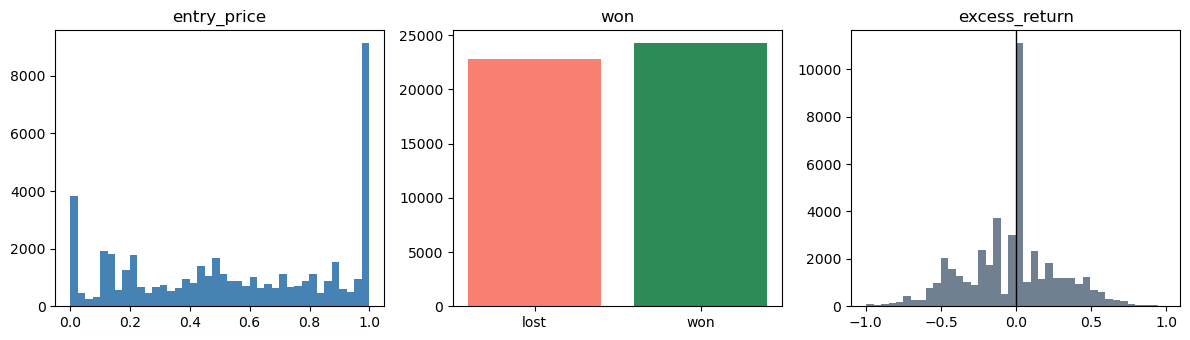

                 count      mean       std    min       25%    50%       75%       max
entry_price    46984.0  0.550425  0.340968  0.001  0.218151  0.540  0.884071  0.999000
won            46984.0  0.515558  0.499763  0.000  0.000000  1.000  1.000000  1.000000
excess_return  46984.0 -0.034867  0.311918 -0.998 -0.210000  0.001  0.122278  0.991024
mean excess return: -0.03486693621425285
by outcome:
          count      mean       std
outcome                           
No       22027 -0.014337  0.302619
Yes      24957 -0.052987  0.318811


In [9]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.5))
ax[0].hist(episodes["entry_price"], bins=40, color="steelblue", edgecolor="none")
ax[0].set_title("entry_price")
ax[1].bar(["lost","won"], episodes["won"].value_counts().sort_index(), color=["salmon","seagreen"])
ax[1].set_title("won")
ax[2].hist(episodes["excess_return"], bins=40, color="slategray", edgecolor="none")
ax[2].axvline(0, color="black", lw=1)
ax[2].set_title("excess_return")
plt.tight_layout(); plt.show()
print(episodes[["entry_price","won","excess_return"]].describe().T)
print("mean excess return:", episodes["excess_return"].mean())
print("by outcome:\n", episodes.groupby("outcome")["excess_return"].agg(["count","mean","std"]))


## 9. EDA — features (raw, then log where planned)


missing rates:


size_vs_self          0.0
size_vs_market        0.0
lead_time_hours       0.0
same_event_share      0.0
entry_price           0.0
log_unique_markets    0.0
account_age_hours     0.0
concentration         0.0
Name: frac_missing, dtype: float64

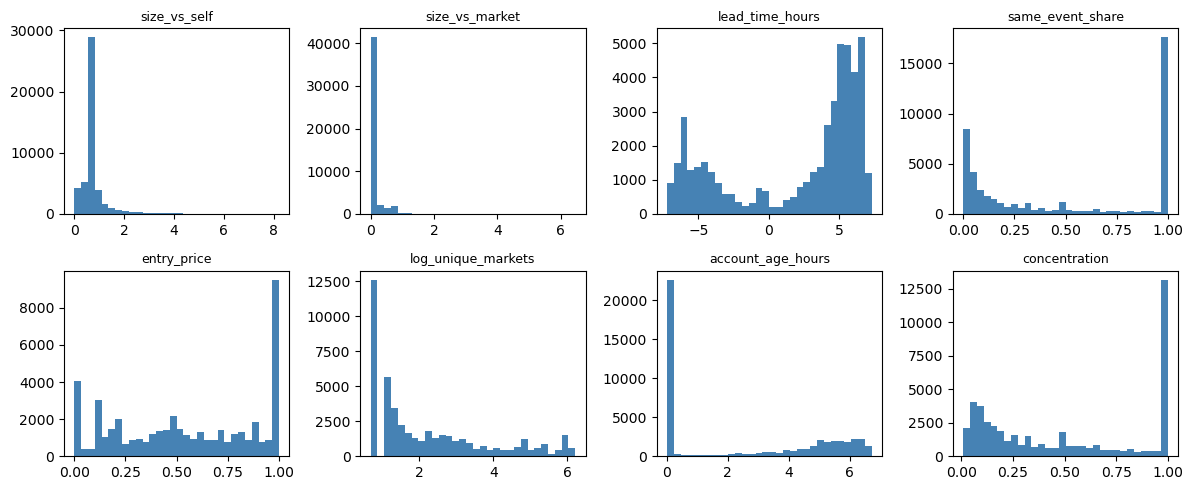

corr with excess_return:
 concentration        -0.124774
same_event_share     -0.122518
lead_time_hours      -0.061972
size_vs_self          0.000608
size_vs_market        0.001909
account_age_hours     0.063404
log_unique_markets    0.102824
entry_price           0.170239
Name: excess_return, dtype: float64


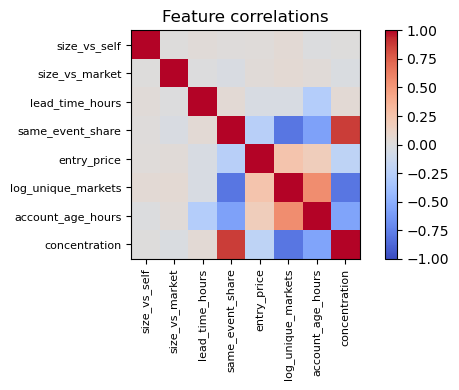

In [10]:
# log transforms per plan
X = episodes[FEATURE_COLS].copy()
for c in ["size_vs_self", "size_vs_market", "lead_time_hours", "account_age_hours"]:
    # lead_time can be negative; use signed log1p of abs with sign, or shift — use log1p of clipped positive hours for age/ratios; for lead_time use asinh
    pass
X_plot = X.copy()
X_plot["size_vs_self"] = np.log1p(X_plot["size_vs_self"].clip(lower=0))
X_plot["size_vs_market"] = np.log1p(X_plot["size_vs_market"].clip(lower=0))
X_plot["lead_time_hours"] = np.arcsinh(X_plot["lead_time_hours"])
X_plot["account_age_hours"] = np.log1p(X_plot["account_age_hours"].clip(lower=0))

print("missing rates:")
display(episodes[FEATURE_COLS].isna().mean().rename("frac_missing"))

fig, axes = plt.subplots(2, 4, figsize=(12, 5))
for ax, c in zip(axes.ravel(), FEATURE_COLS):
    s = X_plot[c].dropna()
    ax.hist(s, bins=30, color="steelblue", edgecolor="none")
    ax.set_title(c, fontsize=9)
plt.tight_layout(); plt.show()

# correlation with label
corr = episodes[FEATURE_COLS + ["excess_return"]].corr()["excess_return"].drop("excess_return")
print("corr with excess_return:\n", corr.sort_values())
fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(episodes[FEATURE_COLS].corr(), cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(8)); ax.set_yticks(range(8))
ax.set_xticklabels(FEATURE_COLS, rotation=90, fontsize=8)
ax.set_yticklabels(FEATURE_COLS, fontsize=8)
fig.colorbar(im, ax=ax, fraction=0.046)
ax.set_title("Feature correlations")
plt.tight_layout(); plt.show()


## 10. Temporal split sanity (by market resolved_at)


In [11]:
# 70/30 by unique markets ordered by resolved_at
mres = episodes.groupby("market")["resolved_at"].min().sort_values()
cut = int(0.7 * len(mres))
train_markets = set(mres.index[:cut])
test_markets = set(mres.index[cut:])
tr = episodes[episodes["market"].isin(train_markets)]
te = episodes[episodes["market"].isin(test_markets)]
assert len(set(tr["market"]) & set(te["market"])) == 0
print(f"train markets {len(train_markets):,} episodes {len(tr):,} mean ER {tr['excess_return'].mean():.4f}")
print(f"test  markets {len(test_markets):,} episodes {len(te):,} mean ER {te['excess_return'].mean():.4f}")
print(f"wallets overlapping splits: {len(set(tr['wallet']) & set(te['wallet'])):,}")
print("train resolved_at:", tr["resolved_at"].min(), "→", tr["resolved_at"].max())
print("test  resolved_at:", te["resolved_at"].min(), "→", te["resolved_at"].max())


train markets 1,005 episodes 38,862 mean ER -0.0425
test  markets 431 episodes 8,122 mean ER 0.0017
wallets overlapping splits: 1,946
train resolved_at: 2026-09-01 12:50:31+00:00 → 2026-09-30 20:53:44+00:00
test  resolved_at: 2026-09-30 21:44:59+00:00 → 2026-10-27 01:13:39.943634+00:00


## 11. PCA preview on training features (~90% variance)


components for ≥90% variance: k=5
variance ratios: [0.442 0.147 0.131 0.1   0.095 0.044 0.025 0.016]
cumulative: [0.442 0.589 0.721 0.821 0.916 0.96  0.984 1.   ]


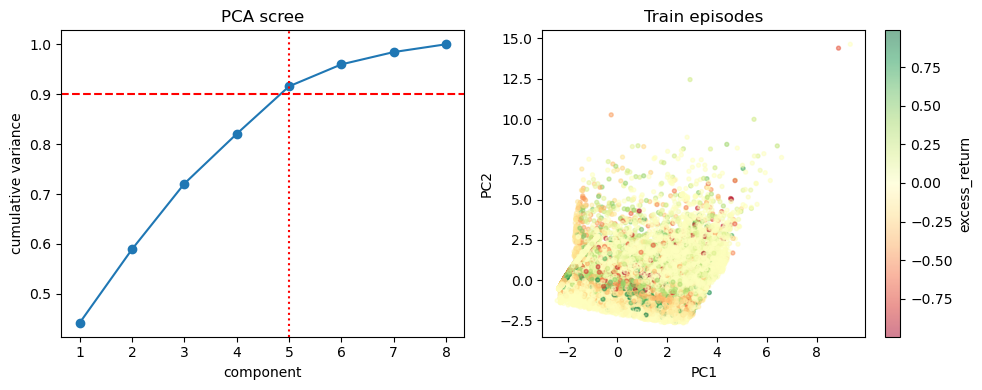

loadings (first k≤3):


,PC1,PC2,PC3
size_vs_self,0.055766,0.681547,0.349938
size_vs_market,0.233652,0.428737,-0.000918
lead_time_hours,-0.056289,-0.102386,0.895878
same_event_share,-0.487880,0.174692,-0.059972
entry_price,0.205689,0.503588,-0.246051
log_unique_markets,0.484344,-0.014679,0.039639
account_age_hours,0.437214,-0.166889,-0.026032
concentration,-0.482751,0.170324,-0.092516


In [12]:
# prepare matrix: log + standardize; drop rows with any NaN in features
def prep(df):
    Z = df[FEATURE_COLS].copy()
    Z["size_vs_self"] = np.log1p(Z["size_vs_self"].clip(lower=0))
    Z["size_vs_market"] = np.log1p(Z["size_vs_market"].clip(lower=0))
    Z["lead_time_hours"] = np.arcsinh(Z["lead_time_hours"].fillna(0))
    Z["account_age_hours"] = np.log1p(Z["account_age_hours"].clip(lower=0))
    return Z

Ztr = prep(tr).dropna()
idx = Ztr.index
scaler = StandardScaler()
Xs = scaler.fit_transform(Ztr)
pca = PCA()
pcs = pca.fit_transform(Xs)
cum = np.cumsum(pca.explained_variance_ratio_)
k = int(np.searchsorted(cum, 0.90) + 1)
print(f"components for ≥90% variance: k={k}")
print("variance ratios:", np.round(pca.explained_variance_ratio_, 3))
print("cumulative:", np.round(cum, 3))

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
ax[0].plot(range(1, 9), cum, marker="o")
ax[0].axhline(0.9, color="red", ls="--")
ax[0].axvline(k, color="red", ls=":")
ax[0].set_xlabel("component"); ax[0].set_ylabel("cumulative variance"); ax[0].set_title("PCA scree")
sc = ax[1].scatter(pcs[:,0], pcs[:,1], c=tr.loc[idx, "excess_return"], cmap="RdYlGn", s=8, alpha=0.5)
fig.colorbar(sc, ax=ax[1], label="excess_return")
ax[1].set_xlabel("PC1"); ax[1].set_ylabel("PC2"); ax[1].set_title("Train episodes")
plt.tight_layout(); plt.show()

loadings = pd.DataFrame(pca.components_[:min(k,3)].T, index=FEATURE_COLS, columns=[f"PC{i+1}" for i in range(min(k,3))])
print("loadings (first k≤3):")
display(loadings)


## 12. Phase 1 takeaways

Fill in after the run (numbers come from cells above):

- Econ/finance filter via Gamma tags → local market list; sample-day keep rate printed in §3.
- Episodes are resolved Yes/No buys only; excess return distribution in §8.
- Feature missingness and correlations in §9 — confirm label is not among features.
- Train/test by `resolved_at` with no shared markets (§10).
- PCA k for ~90% variance (§11).
- **Limitation:** wallet aggregates for size-vs-self / concentration / unique markets use the **cached trade window**, not full lifetime before Sep 1.
- **Next (Phase 2):** Isolation Forest + polynomial/ridge regression + top-1% overlap table on held-out markets.

Cached files in `data/episodes/`: `econ_finance_event_slugs.parquet`, `econ_finance_market_slugs.parquet`, `buys_raw.parquet`, `episodes.parquet`.
